In [1]:
import re
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import curve_fit
from scipy.stats import norm
from scipy.stats import moyal

In [2]:
PLOTS_DIR = Path("plots")
PLOTS_DIR.mkdir(exist_ok=True)

def save_plot(filename=None):
    figure = plt.gcf()
    if filename is None:
        title = figure.axes[0].get_title() if figure.axes else "plot"
        filename = re.sub(
            r"[^a-zA-Z0-9_-]+",
            "_",
            title
        ).strip("_").lower()
        filename = filename or "plot"

    figure.savefig(
        PLOTS_DIR / f"{filename}.png",
        dpi=300,
        bbox_inches="tight"
    )

In [9]:
CSV_PATH = "data_1000e.csv"

COLUMN_NAMES = [
    "RunID",
    "EventID",
    "TrackID",
    "Hit",
    "GlobalTime",
    "TimeSinceZero",
    "TrackLenght",
    "PhotonEnergy",
    "PhotonFlightTime",
    "PhotonCreationTime",
    "Process",
    "NSideReflections"
]

DTYPES = {
    "RunID": "int32",
    "EventID": "int32",
    "TrackID": "int32",
    "Hit": "category",
    "GlobalTime": "float64",
    "TimeSinceZero": "float64",
    "TrackLenght": "float32",
    "PhotonEnergy": "float32",
    "PhotonFlightTime": "float32",
    "PhotonCreationTime": "float32",
    "Process": "category",
    "NSideReflections": "int32",
}

data = pd.read_csv(CSV_PATH, comment="#", header=None, names=COLUMN_NAMES, dtype=DTYPES)

counts_data = len(data)
counts_events = data['EventID'].nunique()

print(f"{counts_data:,} Photon-Treffer geladen, {counts_events:,} Events")
data.head()

data["WavelengthNM"] = (1239.841984 / data["PhotonEnergy"])

1,994,560 Photon-Treffer geladen, 1,000 Events


In [37]:
# masks
mask_process_scintillation = data["Process"] == "Scintillation"
mask_process_cerenkov = data["Process"] == "Cerenkov"

mask_hit_top = data["Hit"] == "top"
mask_hit_bottom = data["Hit"] == "bottom"

# all data
data_all = data.copy()

# only Scintillation
data_all_scintillation = data[
    mask_process_scintillation
].copy()

# only Cerenkov
data_all_cerenkov = data[
    mask_process_cerenkov
].copy()

# only top data all
data_all_top = data[
    mask_hit_top
].copy()

# only top data scintillation
data_all_top_scintillation = data[
    (mask_hit_top)
    &
    (mask_process_scintillation)
].copy()

# only top data cerenkov
data_all_top_cerenkov = data[
    (mask_hit_top)
    &
    (mask_process_cerenkov)
].copy()

# only bottom data all
data_all_bottom = data[
    mask_hit_bottom
].copy()

# only bottom data scintillation
data_all_bottom_scintillation = data[
    (mask_hit_bottom)
    &
    (mask_process_scintillation)
].copy()

# only top data cerenkov
data_all_bottom_cerenkov = data[
    (mask_hit_bottom)
    &
    (mask_process_cerenkov)
].copy()

# arrival times
data_arr_times_all = (
    data_all["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_all_scintillation = (
    data_all_scintillation["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_all_cerenkov = (
    data_all_cerenkov["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_all_top = (
    data_all_top["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_all_bottom = (
    data_all_bottom["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_top_scintillation = (
    data_all_top_scintillation["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_top_cerenkov = (
    data_all_top_cerenkov["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_bottom_scintillation = (
    data_all_bottom_scintillation["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_bottom_cerenkov = (
    data_all_bottom_cerenkov["TimeSinceZero"].dropna().to_numpy()
)

data_wavelength_all = (
    data_all["WavelengthNM"].dropna().to_numpy()
)

data_wavelength_scintillation = (
    data_all_scintillation["WavelengthNM"].dropna().to_numpy()
)

data_wavelength_cerenkov = (
    data_all_cerenkov["WavelengthNM"].dropna().to_numpy()
)

# creat groups for every event: access via event17 = events[17]
data_events = {
    event_id: event_data.copy()
    for event_id, event_data in data.groupby("EventID")
}

print("Data loaded!")

Data loaded!


N_threshold =  10: mean = 0.2486 ns, sigma = 16.65 ps, events = 1000
N_threshold =  30: mean = 0.3142 ns, sigma = 20.90 ps, events = 1000
N_threshold =  50: mean = 0.3615 ns, sigma = 25.29 ps, events = 1000
N_threshold =  80: mean = 0.4195 ns, sigma = 31.79 ps, events = 1000
N_threshold = 100: mean = 0.4537 ns, sigma = 35.76 ps, events = 1000
N_threshold = 120: mean = 0.4858 ns, sigma = 40.16 ps, events = 1000
N_threshold = 150: mean = 0.5314 ns, sigma = 46.40 ps, events = 1000
N_threshold = 200: mean = 0.6022 ns, sigma = 56.49 ps, events = 1000
N_threshold = 220: mean = 0.6295 ns, sigma = 60.63 ps, events = 1000
N_threshold = 250: mean = 0.6695 ns, sigma = 67.11 ps, events = 1000
N_threshold = 300: mean = 0.7356 ns, sigma = 78.39 ps, events = 1000


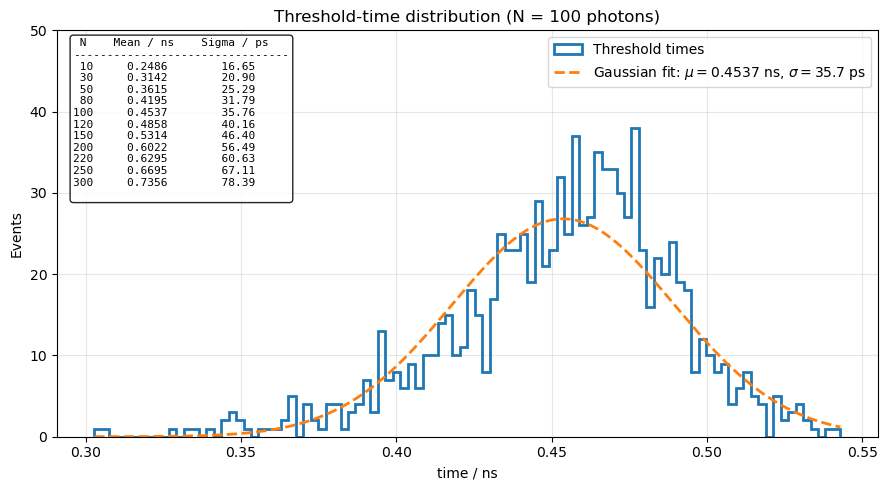

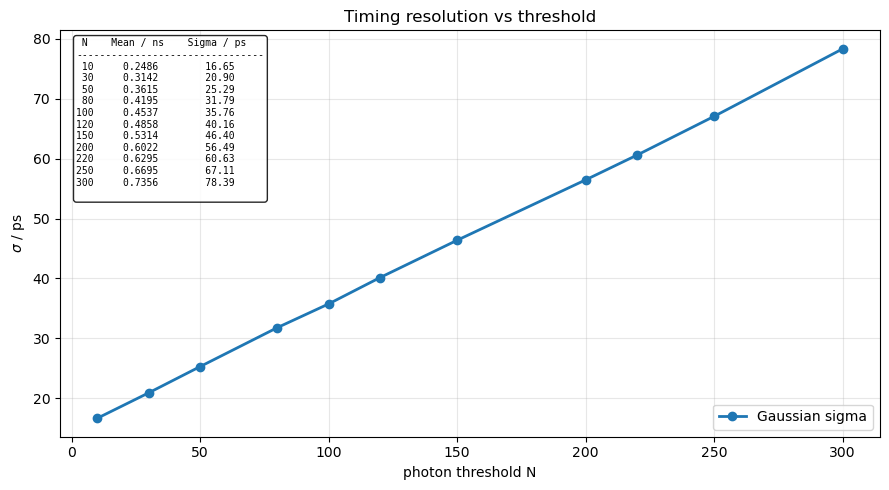

In [36]:
cumulative_photon_thresholds = [
    10, 30, 50, 80, 100, 120, 150, 200, 220, 250, 300
]

# Hier werden die Threshold-Zeiten pro Event gespeichert
threshold_results = []

for event_id, event_data in data_all_scintillation.groupby("EventID"):

    # Ankunftszeiten dieses Events sortieren
    event_times = (
        event_data["TimeSinceZero"]
        .dropna()
        .to_numpy(dtype=float)
    )

    event_times = event_times[
        event_times >= 0
    ]

    event_times = np.sort(event_times)

    result = {
        "EventID": event_id,
        "NPhotons": len(event_times)
    }

    # Alle gewünschten Thresholds bestimmen
    for threshold in cumulative_photon_thresholds:

        if len(event_times) >= threshold:

            result[f"threshold_{threshold}"] = (
                event_times[threshold - 1]
            )

        else:
            result[f"threshold_{threshold}"] = np.nan

    threshold_results.append(result)

# DataFrame mit einem Event pro Zeile
threshold_times = pd.DataFrame(
    threshold_results
)

threshold_statistics = []

for threshold in cumulative_photon_thresholds:

    column = f"threshold_{threshold}"

    times = (
        threshold_times[column]
        .dropna()
        .to_numpy(dtype=float)
    )

    n_events = len(times)

    if n_events > 1:

        mean_time = np.mean(times)

        sigma_time = np.std(
            times,
            ddof=1
        )

        gauss_mean, gauss_sigma = norm.fit(
            times
        )

    else:
        mean_time = np.nan
        sigma_time = np.nan
        gauss_mean = np.nan
        gauss_sigma = np.nan

    threshold_statistics.append({
        "Threshold": threshold,
        "Events": n_events,
        "MeanTime_ns": mean_time,
        "Sigma_ps": sigma_time * 1000,
        "GaussianMean_ns": gauss_mean,
        "GaussianSigma_ps": gauss_sigma * 1000
    })


threshold_statistics = pd.DataFrame(
    threshold_statistics
)

plot_threshold = 100

times_100 = (
    threshold_times[
        f"threshold_{plot_threshold}"
    ]
    .dropna()
    .to_numpy(dtype=float)
)

for _, row in threshold_statistics.iterrows():

    print(
        f"N_threshold = {int(row['Threshold']):3d}: "
        f"mean = {row['MeanTime_ns']:.4f} ns, "
        f"sigma = {row['Sigma_ps']:.2f} ps, "
        f"events = {int(row['Events'])}"
    )

# Gaussian Fit
gauss_mean_100, gauss_sigma_100 = norm.fit(
    times_100
)

# Histogramm
bins = 100

fig, ax = plt.subplots(
    figsize=(9, 5)
)

counts, bin_edges, _ = ax.hist(
    times_100,
    bins=bins,
    histtype="step",
    linewidth=2,
    label="Threshold times"
)

bin_width = (
    bin_edges[1]
    - bin_edges[0]
)

fit_times = np.linspace(
    bin_edges[0],
    bin_edges[-1],
    5000
)

fit_counts = (
    len(times_100)
    * bin_width
    * norm.pdf(
        fit_times,
        loc=gauss_mean_100,
        scale=gauss_sigma_100
    )
)

ax.plot(
    fit_times,
    fit_counts,
    linewidth=2,
    linestyle="--",
    label=(
        rf"Gaussian fit: "
        rf"$\mu={gauss_mean_100:.4f}$ ns, "
        rf"$\sigma={gauss_sigma_100 * 1000:.1f}$ ps"
    )
)

stats_text = " N    Mean / ns    Sigma / ps\n"
stats_text += "-" * 32 + "\n"

for _, row in threshold_statistics.iterrows():
    stats_text += (
        f"{int(row['Threshold']):3d}   "
        f"{row['MeanTime_ns']:8.4f}     "
        f"{row['Sigma_ps']:8.2f}\n"
    )

ax.text(
    0.02, 0.98,
    stats_text,
    transform=ax.transAxes,
    fontsize=8,
    fontfamily="monospace",
    verticalalignment="top",
    horizontalalignment="left",
    bbox=dict(
        boxstyle="round",
        facecolor="white",
        alpha=0.85
    )
)
ax.set_xlabel("time / ns")
ax.set_ylabel("Events")

ax.set_title(
    f"Threshold-time distribution "
    f"(N = {plot_threshold} photons)"
)

ax.set_ylim(top=50)

ax.grid(alpha=0.3)
ax.legend()

fig.tight_layout()

save_plot(
    "threshold_100_photons_gaussian_fit"
)

plt.show()


# Sigma der Gauss-Fits gegen Photon-Threshold
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    threshold_statistics["Threshold"],
    threshold_statistics["GaussianSigma_ps"],
    marker="o",
    linewidth=2,
    label="Gaussian sigma"
)

stats_text = " N    Mean / ns    Sigma / ps\n"
stats_text += "-" * 32 + "\n"

for _, row in threshold_statistics.iterrows():
    stats_text += (
        f"{int(row['Threshold']):3d}   "
        f"{row['MeanTime_ns']:8.4f}     "
        f"{row['Sigma_ps']:8.2f}\n"
    )

ax.text(
    0.02, 0.98,
    stats_text,
    transform=ax.transAxes,
    fontsize=7,
    fontfamily="monospace",
    verticalalignment="top",
    horizontalalignment="left",
    bbox=dict(
        boxstyle="round",
        facecolor="white",
        alpha=0.85
    )
)

ax.set_xlabel("photon threshold N")
ax.set_ylabel(r"$\sigma$ / ps")
ax.set_title("Timing resolution vs threshold")

ax.grid(alpha=0.3)
ax.legend(loc="lower right")

fig.tight_layout()

save_plot("timing_resolution_vs_threshold")

plt.show()

In [20]:
# Auswertung getrennt für top und bottom (nur Szintillationslicht)

def compute_threshold_times(df, thresholds):
    # Zeit, zu der das N-te Photon pro Event eintrifft
    rows = []

    for event_id, event_data in df.groupby("EventID"):
        event_times = event_data["TimeSinceZero"].dropna().to_numpy(dtype=float)
        event_times = np.sort(event_times[event_times >= 0])

        row = {"EventID": event_id, "NPhotons": len(event_times)}

        for threshold in thresholds:
            row[f"threshold_{threshold}"] = (
                event_times[threshold - 1]
                if len(event_times) >= threshold
                else np.nan
            )

        rows.append(row)

    return pd.DataFrame(rows)


def compute_threshold_statistics(times_df, thresholds):
    rows = []

    for threshold in thresholds:
        times = times_df[f"threshold_{threshold}"].dropna().to_numpy(dtype=float)

        if len(times) > 1:
            gauss_mean, gauss_sigma = norm.fit(times)
            mean_time = np.mean(times)
            sigma_time = np.std(times, ddof=1)
        else:
            mean_time = sigma_time = gauss_mean = gauss_sigma = np.nan

        rows.append({
            "Threshold": threshold,
            "Events": len(times),
            "MeanTime_ns": mean_time,
            "Sigma_ps": sigma_time * 1000,
            "GaussianMean_ns": gauss_mean,
            "GaussianSigma_ps": gauss_sigma * 1000,
        })

    return pd.DataFrame(rows)


sides = {
    "top": data_all_top_scintillation,
    "bottom": data_all_bottom_scintillation,
}

side_threshold_times = {}
side_threshold_statistics = {}

for side, side_data in sides.items():
    side_threshold_times[side] = compute_threshold_times(
        side_data, cumulative_photon_thresholds
    )
    side_threshold_statistics[side] = compute_threshold_statistics(
        side_threshold_times[side], cumulative_photon_thresholds
    )

    n_photons = side_threshold_times[side]["NPhotons"]
    print(
        f"\n{side.upper()} (nur Szintillation): "
        f"{len(side_data):,} Photonen, "
        f"{n_photons.mean():.1f} Photonen/Event im Mittel "
        f"(min {n_photons.min()}, max {n_photons.max()})"
    )
    print(side_threshold_statistics[side].round(4).to_string(index=False))


TOP (nur Szintillation): 958,626 Photonen, 958.6 Photonen/Event im Mittel (min 651, max 4012)
 Threshold  Events  MeanTime_ns  Sigma_ps  GaussianMean_ns  GaussianSigma_ps
        10    1000       0.2859   22.5231           0.2859           22.5119
        30    1000       0.3811   31.9586           0.3811           31.9426
        50    1000       0.4533   40.0704           0.4533           40.0503
        80    1000       0.5460   52.1702           0.5460           52.1441
       100    1000       0.6027   60.6219           0.6027           60.5916
       120    1000       0.6569   68.7761           0.6569           68.7417
       150    1000       0.7359   82.1837           0.7359           82.1426
       200    1000       0.8677  106.3300           0.8677          106.2768
       220    1000       0.9203  116.6174           0.9203          116.5591
       250    1000       1.0013  133.0766           1.0013          133.0101
       300    1000       1.1413  164.9972           1.1413

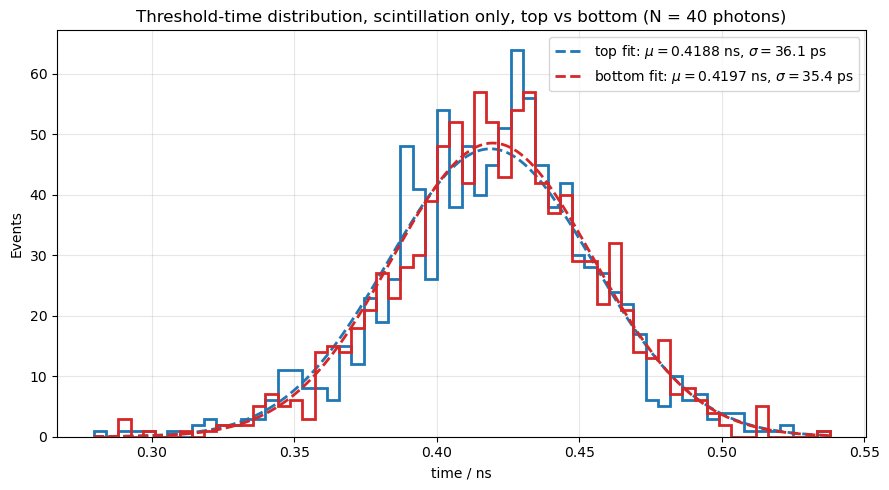

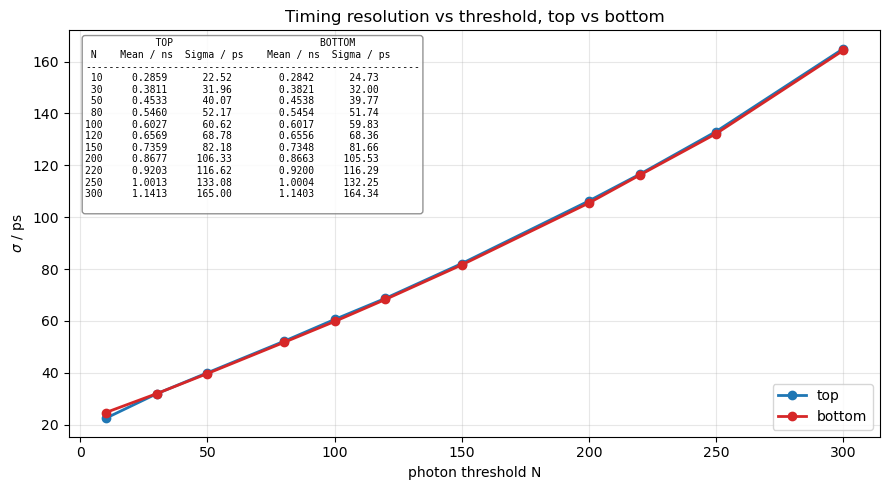

In [ ]:
# top und bottom in einem Plot: Threshold-Zeiten bei N Photonen
plot_threshold = 40
side_colors = {"top": "tab:blue", "bottom": "tab:red"}

# direkt berechnet, damit plot_threshold nicht in cumulative_photon_thresholds stehen muss
times_by_side = {
    side: compute_threshold_times(side_data, [plot_threshold])[
        f"threshold_{plot_threshold}"
    ]
    .dropna()
    .to_numpy(dtype=float)
    for side, side_data in sides.items()
}

# gemeinsame Bins, damit beide Histogramme direkt vergleichbar sind
all_times = np.concatenate(list(times_by_side.values()))
side_bin_edges = np.linspace(all_times.min(), all_times.max(), 61)
side_bin_width = side_bin_edges[1] - side_bin_edges[0]
side_fit_times = np.linspace(side_bin_edges[0], side_bin_edges[-1], 5000)

fig, ax = plt.subplots(figsize=(9, 5))

for side, side_times in times_by_side.items():
    fit_mean, fit_sigma = norm.fit(side_times)

    ax.hist(
        side_times,
        bins=side_bin_edges,
        histtype="step",
        linewidth=2,
        color=side_colors[side],
    )

    ax.plot(
        side_fit_times,
        len(side_times)
        * side_bin_width
        * norm.pdf(side_fit_times, loc=fit_mean, scale=fit_sigma),
        linewidth=2,
        linestyle="--",
        color=side_colors[side],
        label=(
            rf"{side} fit: $\mu={fit_mean:.4f}$ ns, "
            rf"$\sigma={fit_sigma * 1000:.1f}$ ps"
        ),
    )

ax.set_xlabel("time / ns")
ax.set_ylabel("Events")
ax.set_title(
    f"Threshold-time distribution, scintillation only, top vs bottom "
    f"(N = {plot_threshold} photons)"
)
ax.grid(alpha=0.3)
ax.legend()

fig.tight_layout()

save_plot("threshold_100_photons_top_vs_bottom_scintillation")

plt.show()

# Zeitauflösung (Gauss-sigma) in Abhängigkeit vom Schwellenwert
fig, ax = plt.subplots(figsize=(9, 5))

for side, stats in side_threshold_statistics.items():
    ax.plot(
        stats["Threshold"],
        stats["GaussianSigma_ps"],
        marker="o",
        linewidth=2,
        color=side_colors[side],
        label=side,
    )

ax.set_xlabel("photon threshold N")
ax.set_ylabel(r"$\sigma$ / ps")
ax.set_title("Timing resolution vs threshold, top vs bottom")

ax.grid(alpha=0.3)
ax.legend()

ax.legend(loc="lower right")

# Statistik-Textbox für Top und Bottom
stats_text = (
    "            TOP                         BOTTOM\n"
    " N    Mean / ns  Sigma / ps    Mean / ns  Sigma / ps\n"
    + "-" * 57 + "\n"
)

stats_top = side_threshold_statistics["top"]
stats_bottom = side_threshold_statistics["bottom"]

for (_, top), (_, bottom) in zip(
    stats_top.iterrows(),
    stats_bottom.iterrows()
):
    stats_text += (
        f"{int(top['Threshold']):3d}   "
        f"{top['MeanTime_ns']:8.4f}   "
        f"{top['Sigma_ps']:8.2f}      "
        f"{bottom['MeanTime_ns']:8.4f}   "
        f"{bottom['Sigma_ps']:8.2f}\n"
    )

ax.text(
    0.02, 0.98,
    stats_text,
    transform=ax.transAxes,
    fontsize=7,
    fontfamily="monospace",
    verticalalignment="top",
    horizontalalignment="left",
    bbox=dict(
        boxstyle="round",
        facecolor="white",
        edgecolor="gray",
        alpha=0.85
    )
)

fig.tight_layout()

save_plot("timing_resolution_vs_threshold_top_vs_bottom_scintillation")

plt.show()